In [26]:
!pip install drms
!pip install sunpy[all]
!pip install astropy
!pip install streamtracer

In [27]:
!pip install pfsspy

In [28]:
import sunpy.map
import pfsspy
from pfsspy import utils
import pfsspy.tracing
import matplotlib.pyplot as plt
import numpy as np
import os
import warnings
import astropy.units as u
from sunpy.net import Fido, attrs as a

In [29]:
time=a.Time("2025-01-22T01:30:00", "2025-01-22T01:30:12")
series = a.jsoc.Series('hmi.synoptic_mr_polfil_720s')
crot = a.jsoc.PrimeKey('CAR_ROT', 2293)
# Define the email notification directly
notify = a.jsoc.Notify('kutsunodozo@gmail.com')
hmi_results = Fido.search(time,series,crot,notify)
print(hmi_results)

Results from 1 Provider:

1 Results from the JSOCClient:
Source: http://jsoc.stanford.edu

TELESCOP  INSTRUME WAVELNTH CAR_ROT
-------- --------- -------- -------
 SDO/HMI HMI_SIDE1   6173.0    2293




In [30]:
warnings.filterwarnings("ignore")
downloaded_file1 = Fido.fetch(hmi_results,path="/content/hmi")# Download and load the map

INFO:sunpy:1 URLs found for download. Full request totaling 4MB


INFO: 1 URLs found for download. Full request totaling 4MB [sunpy.net.jsoc.jsoc]


Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

hmi.synoptic_mr_polfil_720s.2293.Mr_polfil.fits:   0%|          | 0.00/4.64M [00:00<?, ?B/s]

In [31]:
filenm =r'/content/hmi/hmi.synoptic_mr_polfil_720s.2293.Mr_polfil.fits'

hmi_map = sunpy.map.Map(filenm)
print(hmi_map.meta)

('simple': 'True')
('bitpix': '32')
('naxis': '2')
('naxis1': '3600')
('naxis2': '1440')
('blank': '-2147483648')
('n_extrap': '0')
('s_extrap': '0')
('method': 'TEMP_SPAT')
('lat0': '60.0')
('latfil': '75.0')
('latfil1': '62.0')
('nmax': '5')
('date': '2025-10-12T07:29:47.000')
('telescop': 'SDO/HMI')
('instrume': 'HMI_SIDE1')
('wavelnth': '6173.0')
('bunit': 'Mx/cm^2')
('content': 'Carrington Synoptic Chart Of Br Field')
('history': 'Carrington-Time conversion corrected; o2helio.c bug corrected -- July 20
13')
('bld_vers': 'None')
('ctype1': 'CRLN-CEA')
('ctype2': 'CRLT-CEA')
('crpix1': '1800.0')
('crpix2': '720.5')
('crval1': '825300.0')
('crval2': '0.0')
('cdelt1': '-0.1')
('cdelt2': '0.001388888888888889')
('cunit1': 'degree')
('cunit2': 'Sine Latitude')
('crder1': '0.0')
('crder2': '0.0')
('csyser1': 'None')
('csyser2': 'None')
('wcsname': 'Carrington Heliographic')
('cadence': '360.0')
('datasign': '1')
('t_obs': '2025.01.20_11:53:56_TAI')
('t_start': '2025.01.06_19:49:41_TAI')


In [32]:
warnings.filterwarnings("ignore")
# Download and load the map
# downloaded_file1 = Fido.fetch(hmi_results,path="/content/hmi") # This line was already executed in a previous cell

import pfsspy
import pfsspy.utils
pfsspy.utils.fix_hmi_meta(hmi_map)
# Specify data directories and data range
nrho = 60
rss =2.5
# Ensure the map is in cylindrical equal-area (CEA) projection required by pfsspy.
if not pfsspy.utils.is_cea_map(hmi_map):
    hmi_map = pfsspy.utils.car_to_cea(hmi_map)  # reproject Carrington to CEA

# Optionally downsample the HMI map to speed up PFSS computation (e.g., to 360x180 pixels).
hmi_map = hmi_map.resample([360, 180] * u.pix)

# Replace any non-finite values (like NaN) with 0
# hmi_map.data[~np.isfinite(hmi_map.data)] = 0

# pfss_in =sunkit_magex.pfss.Input(hmi_map, nrho, rss)
# pfss_out= sunkit_magex.pfss.pfss(pfss_in)
pfss_in =pfsspy.Input(hmi_map, nrho, rss)
pfss_out= pfsspy.pfss(pfss_in)

INFO:sunpy:Missing metadata for solar radius: assuming the standard radius of the photosphere.
INFO:sunpy:Missing metadata for solar radius: assuming the standard radius of the photosphere.
INFO:sunpy:Missing metadata for solar radius: assuming the standard radius of the photosphere.
INFO:sunpy:Missing metadata for solar radius: assuming the standard radius of the photosphere.


INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


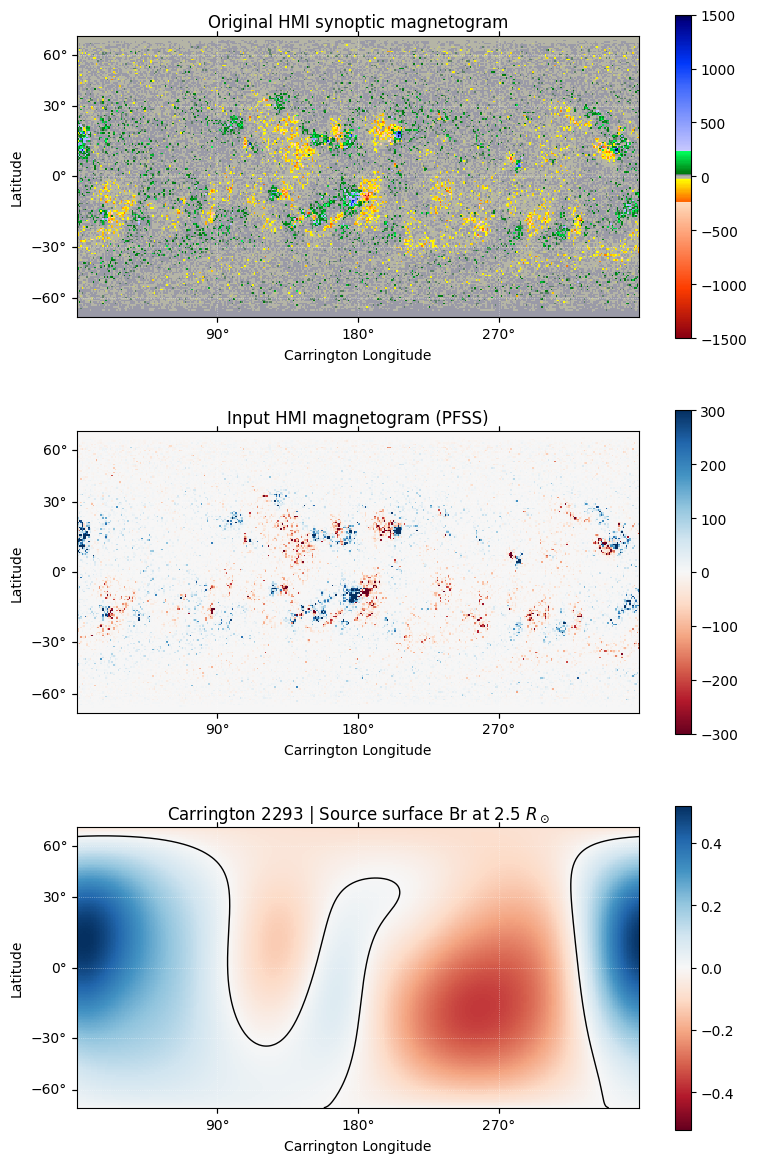

In [33]:
m = pfss_in.map
ss_br = pfss_out.source_surface_br

fig = plt.figure(figsize=(8, 12))

# Panel 1: Original HMI map
ax = fig.add_subplot(3, 1, 1, projection=hmi_map)
im = hmi_map.plot()
plt.colorbar(im, ax=ax)
ax.set_title('Original HMI synoptic magnetogram')

# Panel 2: Input map for PFSS
ax = fig.add_subplot(3, 1, 2, projection=m)
im = m.plot(norm=None,vmin=-300,vmax=300)
plt.colorbar(im, ax=ax)
ax.set_title('Input HMI magnetogram (PFSS)')

# Panel 3: Source surface magnetic field
ax = fig.add_subplot(3, 1, 3, projection=ss_br)
im = ss_br.plot()
for pil in pfss_out.source_surface_pils:
    ax.plot_coord(pil, color='k', linewidth=1)
plt.colorbar(im, ax=ax)
ax.set_title(f"Carrington {2293} | Source surface Br at {rss} $R_\\odot$")

plt.tight_layout()
plt.show()

In [34]:
# Define function to do the field line tracing
def pfss2flines(pfsspy_output, # pfsspy output object
                nth=41,nph=92, # number of tracing grid points
                rect=[-90,90,0,360], #sub-region of sun to trace (default is whole sun)
                trace_from_SS=False, # if False : start trace from photosphere,
                                     #if True, start tracing from source surface
                skycoord_in=None, # Use custom set of starting grid poitns
                max_steps = 1000 # max steps tracer should take before giving up
                ) :

    # Tracing if grid
    if skycoord_in is None  :
        [latmin,latmax,lonmin,lonmax]=rect
        lons,lats = np.meshgrid(np.linspace(lonmin,lonmax,nph),
                                np.linspace(latmin,latmax,nth)
                                )
        if not trace_from_SS : alt = 1.0*u.R_sun # Trace up from photosphere
        else : alt = pfsspy_output.grid.rss*u.R_sun  # Trace down from ss
        alt = [alt]*len(lons.ravel())
        seeds = astropy.coordinates.SkyCoord(lons.ravel()*u.deg,
                               lats.ravel()*u.deg,
                               alt,
                               frame = pfsspy_output.coordinate_frame)

    # Tracing if custom set of points
    else :
        skycoord_in.representation_type = "heliographic_carrington"
        seeds = astropy.coordinates.SkyCoord(skycoord_in.lon,
                               skycoord_in.lat,
                               skycoord_in.radius,
                               frame = pfsspy_output.coordinate_frame)

    return pfsspy_output.trace(pfsspy.tracing.FortranTracer(max_steps=max_steps),seeds)

In [35]:
import astropy
from astropy.coordinates import SkyCoord
import pfsspy.tracing

# Trace closed (from photosphere) and open (from source surface)
flines = pfss2flines(pfss_out, nth=36, nph=72, trace_from_SS=False)
flines_ss = pfss2flines(pfss_out, nth=36, nph=72, trace_from_SS=True)

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from sunpy.coordinates import sun

def sph2orthographic(r, lon, lat, lon0=0*u.deg, lat0=0*u.deg):
    """
    Orthographic projection of (r, lon, lat) as seen from (lon0, lat0).
    Returns x, y only for visible points.
    """
    # Convert to radians
    lon = lon.to_value(u.rad)
    lat = lat.to_value(u.rad)
    lon0 = lon0.to_value(u.rad)
    lat0 = lat0.to_value(u.rad)

    # Angular difference, wrapped
    dlon = (lon - lon0 + np.pi) % (2*np.pi) - np.pi

    # Central angle between point and sub-Earth point
    cos_c = np.sin(lat0)*np.sin(lat) + np.cos(lat0)*np.cos(lat)*np.cos(dlon)
    visible = cos_c > 0

    # Orthographic projection
    x = r * np.cos(lat) * np.sin(dlon)
    y = r * (np.cos(lat0)*np.sin(lat) - np.sin(lat0)*np.cos(lat)*np.cos(dlon))
    return x[visible], y[visible], visible


def plot_pfss_orthographic(pfss_out, flines, flines_ss, lon0=0, lat0=None):
    """
    Plot PFSS field lines and magnetic neutral line (MNL)
    in an orthographic Earth-view projection.
    """
    fig, ax = plt.subplots(figsize=(6, 6), dpi=150)

    rss = pfss_out.grid.rss  # source surface radius (at 2.5 R_s)
    if lat0 is None:
        # Actual solar B0 tilt
        lat0 = sun.B0(pfss_out.source_surface_br.date)

    # Grid
    for lat_deg in range(-90, 91, 10):
        lons = np.linspace(0, 360, 180) * u.deg
        lats = np.full(lons.shape, lat_deg) * u.deg
        x, y, _ = sph2orthographic(rss, lons, lats, lon0*u.deg, lat0)
        ax.plot(x, y, 'gray', lw=0.3, alpha=0.3)

    for lon_deg in range(0, 360, 30):
        lats = np.linspace(-90, 90, 180) * u.deg
        lons = np.full(lats.shape, lon_deg) * u.deg
        x, y, _ = sph2orthographic(rss, lons, lats, lon0*u.deg, lat0)
        ax.plot(x, y, 'gray', lw=0.3, alpha=0.3)


    # Magnetic Neutral Line (MNL)
    for pil in pfss_out.source_surface_pils:
        pil.representation_type = 'spherical'

        # Convert to numpy arrays
        lon = pil.lon.to_value(u.deg)
        lat = pil.lat.to_value(u.deg)

        # Unwrap longitude to avoid discontinuities (e.g., 359 to 0)
        lon = np.unwrap(np.radians(lon)) * u.rad
        lat = lat * u.deg

        # Project to orthographic view
        x_mnl, y_mnl, visible = sph2orthographic(rss, lon, lat, lon0*u.deg, lat0)

        # If visibility is broken into chunks (due to limb), split and plot separately
        if len(x_mnl) == 0:
            continue

        # Split visible regions where visibility toggles
        vis_idx = np.where(np.diff(visible.astype(int)) != 0)[0]
        seg_edges = np.concatenate(([0], vis_idx + 1, [len(visible)]))

        for i in range(len(seg_edges) - 1):
            seg_slice = slice(seg_edges[i], seg_edges[i + 1])
            if not np.any(visible[seg_slice]):
                continue
            x_seg, y_seg, _ = sph2orthographic(rss, lon[seg_slice], lat[seg_slice], lon0*u.deg, lat0)
            ax.plot(x_seg, y_seg, color='black', lw=1.2, linestyle='--', alpha=0.9)


    # Field Lines
    color_dict = {-1: "blue", 0: "green", 1: "red"}
    for fline in list(flines) + list(flines_ss):
        if fline.coords is None or len(fline.coords.lon) < 2:
            continue
        coords = fline.coords
        coords.representation_type = 'spherical'
        r = coords.radius.to(u.R_sun).value
        lon = coords.lon
        lat = coords.lat
        x_f, y_f, visible = sph2orthographic(r, lon, lat, lon0*u.deg, lat0)
        if len(x_f) == 0:
            continue
        alpha_val = 1.0 if fline in flines else 0.4
        ax.plot(x_f, y_f, color=color_dict.get(fline.polarity, 'gray'),
                lw=0.5, alpha=alpha_val)

    # Circles for 1 R_s and source surface
    ax.add_artist(plt.Circle((0, 0), 1.0, color='k', fill=False, lw=1))
    ax.add_artist(plt.Circle((0, 0), rss, color='k', fill=False, lw=0.8, linestyle=':'))

    # View limits and labels
    ax.set_xlim(-rss, rss)
    ax.set_ylim(-rss, rss)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f"Orthographic View (CMP={lon0}°, B0={lat0.to_value(u.deg):.1f}°)")
    plt.tight_layout()
    plt.show()

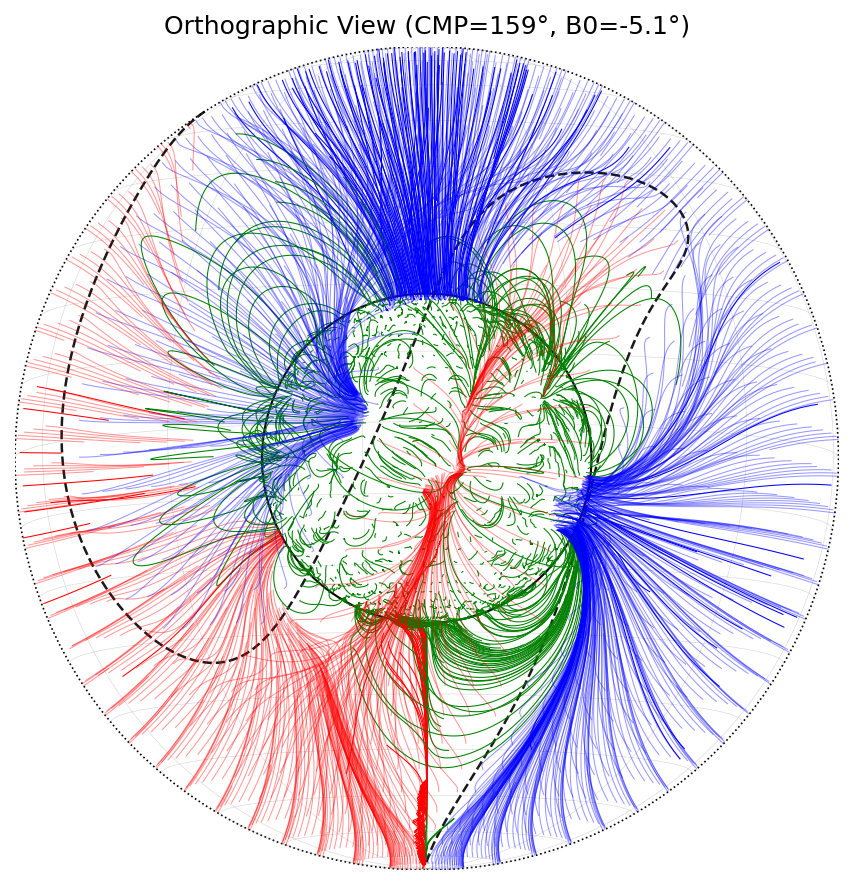

In [37]:
plot_pfss_orthographic(pfss_out, flines, flines_ss, lon0=159)

In [46]:
# Define time range
time = time=a.Time("2025-01-22T01:30:00", "2025-01-22T01:30:12")
series = a.jsoc.Series('hmi.m_45s')

# Combine specific wavelengths: 171, 193, 21\1 Å
# wavelength = (
#     a.Wavelength(6173*u.angstrom))
# Sample cadence
sample = a.Sample(45 * u.second)

# Notification email
notify = a.jsoc.Notify('kutsunodozo@gmail.com')
# results = Fido.search(time, series, wavelength, sample, notify)
results = Fido.search(time, series, sample, notify)

print(results)

Results from 1 Provider:

1 Results from the JSOCClient:
Source: http://jsoc.stanford.edu

         T_REC          TELESCOP  INSTRUME  WAVELNTH CAR_ROT
----------------------- -------- ---------- -------- -------
2025.01.22_01:30:45_TAI  SDO/HMI HMI_FRONT2   6173.0    2293




In [47]:
downloaded_file1 = Fido.fetch(results, path="/content/hmi")

INFO:sunpy:1 URLs found for download. Full request totaling 16MB


INFO: 1 URLs found for download. Full request totaling 16MB [sunpy.net.jsoc.jsoc]


Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

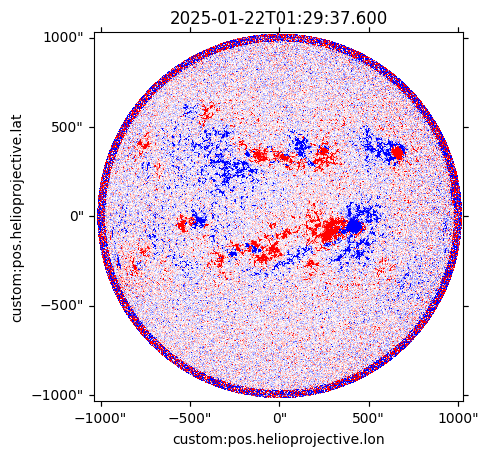

In [51]:
from astropy.io import fits
from sunpy.coordinates import frames
import sunpy.map
import matplotlib.pyplot as plt
import astropy.units as u
import matplotlib.colors
hmi1 = sunpy.map.Map(r'/content/hmi/hmi.m_45s.20250122_013045_TAI.2.magnetogram.fits')
hmi1= hmi1.rotate(order=3)  # 'order=3' uses bicubic interpolation for smoother results

dtime1 = hmi1.date
# hmi.plot()
# hmi.draw_limb()



# from sunpy.data.sample import HMI_LOS_IMAGE

# smap = sunpy.map.Map(HMI_LOS_IMAGE)
fig = plt.figure()
ax = fig.add_subplot(1,1,1, projection=hmi1)
norm = matplotlib.colors.SymLogNorm(100, vmin=-50, vmax=50)
hmi1.plot(axes=ax, cmap="bwr",norm=norm,annotate=False)
# hmi.draw_limb()
plt.title(f'{dtime1}')
plt.show()

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from sunpy.coordinates import sun

def sph2orthographic(r, lon, lat, lon0=0*u.deg, lat0=0*u.deg):
    """
    Orthographic projection of (r, lon, lat) as seen from (lon0, lat0).
    Returns x, y only for visible points.
    """
    # Convert to radians
    lon = lon.to_value(u.rad)
    lat = lat.to_value(u.rad)
    lon0 = lon0.to_value(u.rad)
    lat0 = lat0.to_value(u.rad)

    # Angular difference, wrapped
    dlon = (lon - lon0 + np.pi) % (2*np.pi) - np.pi

    # Central angle between point and sub-Earth point
    cos_c = np.sin(lat0)*np.sin(lat) + np.cos(lat0)*np.cos(lat)*np.cos(dlon)
    visible = cos_c > 0

    # Orthographic projection
    x = r * np.cos(lat) * np.sin(dlon)
    y = r * (np.cos(lat0)*np.sin(lat) - np.sin(lat0)*np.cos(lat)*np.cos(dlon))
    return x[visible], y[visible], visible


def plot_pfss_orthographic_with_hmi(hmi_map, pfss_out, flines, flines_ss, lon0=0,lat0=None):
    fig, ax = plt.subplots(figsize=(4, 4), dpi=150)

    rss = 2.5  # source surface radius

    # Plot HMI Photosphere Disk
    # Assumes hmi_image is a 2D numpy array
    ax.imshow(hmi1.data, origin='lower',cmap="gray",norm=None,vmin=-50,vmax=50,
              extent=[-1, 1, -1, 1], zorder=-1)  # photosphere = radius 1

    # Draw limb
    limb = plt.Circle((0, 0), 0.5, color='k', fill=False, lw=1)
    if lat0 is None:
        # Actual solar B0 tilt
        lat0 = sun.B0(pfss_out.source_surface_br.date)

    # Grid
    for lat_deg in range(-90, 91, 10):
        lons = np.linspace(0, 360, 180) * u.deg
        lats = np.full(lons.shape, lat_deg) * u.deg
        x, y, _ = sph2orthographic(rss, lons, lats, lon0*u.deg, lat0)
        ax.plot(x, y, 'gray', lw=0.3, alpha=0.3)

    for lon_deg in range(0, 360, 30):
        lats = np.linspace(-90, 90, 180) * u.deg
        lons = np.full(lats.shape, lon_deg) * u.deg
        x, y, _ = sph2orthographic(rss, lons, lats, lon0*u.deg, lat0)
        ax.plot(x, y, 'gray', lw=0.3, alpha=0.3)


    # Magnetic Neutral Line (MNL)
    for pil in pfss_out.source_surface_pils:
        pil.representation_type = 'spherical'

        # Convert to numpy arrays
        lon = pil.lon.to_value(u.deg)
        lat = pil.lat.to_value(u.deg)

        # Unwrap longitude to avoid discontinuities (e.g., 359 to 0)
        lon = np.unwrap(np.radians(lon)) * u.rad
        lat = lat * u.deg

        # Project to orthographic view
        x_mnl, y_mnl, visible = sph2orthographic(rss, lon, lat, lon0*u.deg, lat0)

        # If visibility is broken into chunks (due to limb), split and plot separately
        if len(x_mnl) == 0:
            continue

        # Split visible regions where visibility toggles
        vis_idx = np.where(np.diff(visible.astype(int)) != 0)[0]
        seg_edges = np.concatenate(([0], vis_idx + 1, [len(visible)]))

        for i in range(len(seg_edges) - 1):
            seg_slice = slice(seg_edges[i], seg_edges[i + 1])
            if not np.any(visible[seg_slice]):
                continue
            x_seg, y_seg, _ = sph2orthographic(rss, lon[seg_slice], lat[seg_slice], lon0*u.deg, lat0)
            ax.plot(x_seg, y_seg, color='black', lw=1.2, linestyle='--', alpha=0.9)


    # Field Lines
    color_dict = {-1: "blue", 0: "green", 1: "red"}
    for fline in list(flines) + list(flines_ss):
        if fline.coords is None or len(fline.coords.lon) < 2:
            continue
        coords = fline.coords
        coords.representation_type = 'spherical'
        r = coords.radius.to(u.R_sun).value
        lon = coords.lon
        lat = coords.lat
        x_f, y_f, visible = sph2orthographic(r, lon, lat, lon0*u.deg, lat0)
        if len(x_f) == 0:
            continue
        alpha_val = 1.0 if fline in flines else 0.4
        ax.plot(x_f, y_f, color=color_dict.get(fline.polarity, 'gray'),
                lw=0.5, alpha=alpha_val)

    # Circles for 1 R_s and source surface
    ax.add_artist(plt.Circle((0, 0), 1.0, color='k', fill=False, lw=1))
    ax.add_artist(plt.Circle((0, 0), rss, color='k', fill=False, lw=0.8, linestyle=':'))

    # View limits and labels
    ax.set_xlim(-rss, rss)
    ax.set_ylim(-rss, rss)
    ax.set_aspect('equal')
    ax.axis('off')
    # ax.set_title(f"Orthographic View (CMP={lon0}°, B0={lat0.to_value(u.deg):.1f}°)")
    ax.set_title(f"CMP={lon0}°")

    plt.tight_layout()
    plt.show()

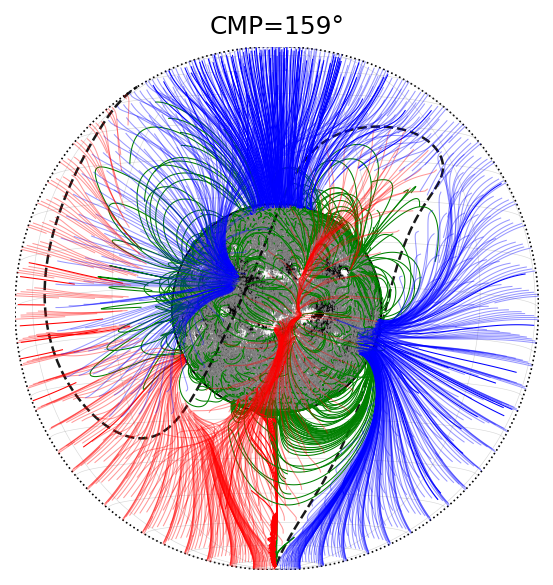

In [53]:
plot_pfss_orthographic_with_hmi(hmi1, pfss_out, flines, flines_ss, lon0=159)
# plt.savefig(r'/content/hmi/PFSS_3D_HMI_CMP_113.pdf',dpi=300)
plt.show()

In [56]:
# Define time range
time = time=a.Time("2025-01-22T13:30:00", "2025-01-22T13:30:12")
series = a.jsoc.Series('hmi.m_45s')

# Combine specific wavelengths: 171, 193, 211 Å
# wavelength = (
#     a.Wavelength(6173*u.angstrom))
# Sample cadence
sample = a.Sample(45 * u.second)

# Notification email
notify = a.jsoc.Notify('kutsunodozo@gmail.com')
# results = Fido.search(time, series, wavelength, sample, notify)
results = Fido.search(time, series, sample, notify)

print(results)

Results from 1 Provider:

1 Results from the JSOCClient:
Source: http://jsoc.stanford.edu

         T_REC          TELESCOP  INSTRUME  WAVELNTH CAR_ROT
----------------------- -------- ---------- -------- -------
2025.01.22_13:30:45_TAI  SDO/HMI HMI_FRONT2   6173.0    2293




In [57]:
downloaded_file1 = Fido.fetch(results, path="/content/hmi")

INFO:sunpy:1 URLs found for download. Full request totaling 16MB


INFO: 1 URLs found for download. Full request totaling 16MB [sunpy.net.jsoc.jsoc]


Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

hmi.m_45s.20250122_133045_TAI.2.magnetogram.fits:   0%|          | 0.00/17.0M [00:00<?, ?B/s]

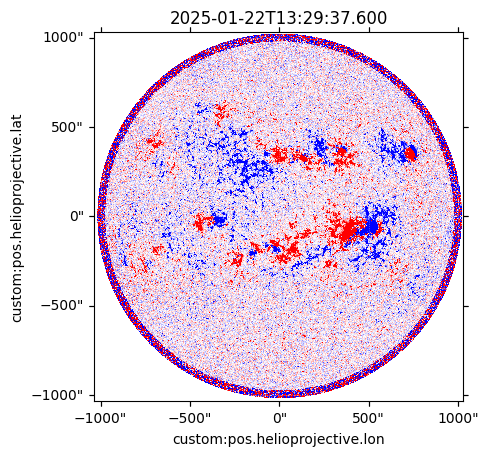

In [58]:
from astropy.io import fits
from sunpy.coordinates import frames
import sunpy.map
import matplotlib.pyplot as plt
import astropy.units as u
import matplotlib.colors
hmi1 = sunpy.map.Map(r'/content/hmi/hmi.m_45s.20250122_133045_TAI.2.magnetogram.fits')
hmi1= hmi1.rotate(order=3)

dtime1 = hmi1.date

# smap = sunpy.map.Map(HMI_LOS_IMAGE)
fig = plt.figure()
ax = fig.add_subplot(1,1,1, projection=hmi1)
norm = matplotlib.colors.SymLogNorm(100, vmin=-50, vmax=50)
hmi1.plot(axes=ax, cmap="bwr",norm=norm,annotate=False)
# hmi.draw_limb()
plt.title(f'{dtime1}')
plt.show()

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from sunpy.coordinates import sun

def sph2orthographic(r, lon, lat, lon0=0*u.deg, lat0=0*u.deg):
    """
    Orthographic projection of (r, lon, lat) as seen from (lon0, lat0).
    Returns x, y only for visible points.
    """
    # Convert to radians
    lon = lon.to_value(u.rad)
    lat = lat.to_value(u.rad)
    lon0 = lon0.to_value(u.rad)
    lat0 = lat0.to_value(u.rad)

    # Angular difference, wrapped
    dlon = (lon - lon0 + np.pi) % (2*np.pi) - np.pi

    # Central angle between point and sub-Earth point
    cos_c = np.sin(lat0)*np.sin(lat) + np.cos(lat0)*np.cos(lat)*np.cos(dlon)
    visible = cos_c > 0

    # Orthographic projection
    x = r * np.cos(lat) * np.sin(dlon)
    y = r * (np.cos(lat0)*np.sin(lat) - np.sin(lat0)*np.cos(lat)*np.cos(dlon))
    return x[visible], y[visible], visible


def plot_pfss_orthographic_with_hmi(hmi_map, pfss_out, flines, flines_ss, lon0=0,lat0=None):
    fig, ax = plt.subplots(figsize=(4, 4), dpi=150)

    rss = 2.5  # source surface radius

    # Plot HMI Photosphere Disk
    # Assumes hmi_image is a 2D numpy array
    ax.imshow(hmi1.data, origin='lower',cmap="gray",norm=None,vmin=-50,vmax=50,
              extent=[-1, 1, -1, 1], zorder=-1)  # photosphere = radius 1

    # Draw limb
    limb = plt.Circle((0, 0), 0.5, color='k', fill=False, lw=1)
    if lat0 is None:
        # Actual solar B0 tilt
        lat0 = sun.B0(pfss_out.source_surface_br.date)

    # Grid
    for lat_deg in range(-90, 91, 10):
        lons = np.linspace(0, 360, 180) * u.deg
        lats = np.full(lons.shape, lat_deg) * u.deg
        x, y, _ = sph2orthographic(rss, lons, lats, lon0*u.deg, lat0)
        ax.plot(x, y, 'gray', lw=0.3, alpha=0.3)

    for lon_deg in range(0, 360, 30):
        lats = np.linspace(-90, 90, 180) * u.deg
        lons = np.full(lats.shape, lon_deg) * u.deg
        x, y, _ = sph2orthographic(rss, lons, lats, lon0*u.deg, lat0)
        ax.plot(x, y, 'gray', lw=0.3, alpha=0.3)


    # Magnetic Neutral Line (MNL)
    for pil in pfss_out.source_surface_pils:
        pil.representation_type = 'spherical'

        # Convert to numpy arrays
        lon = pil.lon.to_value(u.deg)
        lat = pil.lat.to_value(u.deg)

        # Unwrap longitude to avoid discontinuities (e.g., 359 to 0)
        lon = np.unwrap(np.radians(lon)) * u.rad
        lat = lat * u.deg

        # Project to orthographic view
        x_mnl, y_mnl, visible = sph2orthographic(rss, lon, lat, lon0*u.deg, lat0)

        # If visibility is broken into chunks (due to limb), split and plot separately
        if len(x_mnl) == 0:
            continue

        # Split visible regions where visibility toggles
        vis_idx = np.where(np.diff(visible.astype(int)) != 0)[0]
        seg_edges = np.concatenate(([0], vis_idx + 1, [len(visible)]))

        for i in range(len(seg_edges) - 1):
            seg_slice = slice(seg_edges[i], seg_edges[i + 1])
            if not np.any(visible[seg_slice]):
                continue
            x_seg, y_seg, _ = sph2orthographic(rss, lon[seg_slice], lat[seg_slice], lon0*u.deg, lat0)
            ax.plot(x_seg, y_seg, color='black', lw=1.2, linestyle='--', alpha=0.9)


    # Field Lines
    color_dict = {-1: "blue", 0: "green", 1: "red"}
    for fline in list(flines) + list(flines_ss):
        if fline.coords is None or len(fline.coords.lon) < 2:
            continue
        coords = fline.coords
        coords.representation_type = 'spherical'
        r = coords.radius.to(u.R_sun).value
        lon = coords.lon
        lat = coords.lat
        x_f, y_f, visible = sph2orthographic(r, lon, lat, lon0*u.deg, lat0)
        if len(x_f) == 0:
            continue
        alpha_val = 1.0 if fline in flines else 0.4
        ax.plot(x_f, y_f, color=color_dict.get(fline.polarity, 'gray'),
                lw=0.5, alpha=alpha_val)

    # Circles for 1 R_s and source surface
    ax.add_artist(plt.Circle((0, 0), 1.0, color='k', fill=False, lw=1))
    ax.add_artist(plt.Circle((0, 0), rss, color='k', fill=False, lw=0.8, linestyle=':'))

    # View limits and labels
    ax.set_xlim(-rss, rss)
    ax.set_ylim(-rss, rss)
    ax.set_aspect('equal')
    ax.axis('off')
    # ax.set_title(f"Orthographic View (CMP={lon0}°, B0={lat0.to_value(u.deg):.1f}°)")
    ax.set_title(f"CMP={lon0}°")

    plt.tight_layout()
    plt.show()

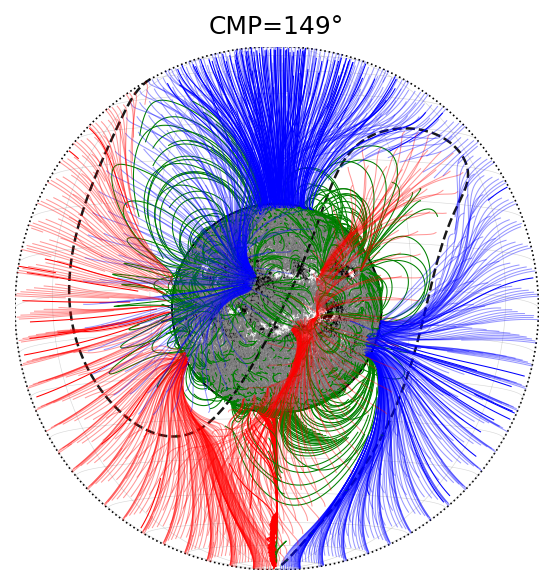

In [60]:
plot_pfss_orthographic_with_hmi(hmi1, pfss_out, flines, flines_ss, lon0=149)
# plt.savefig(r'/content/hmi/PFSS_3D_HMI_CMP_113.pdf',dpi=300)
plt.show()